# Shao–Wu: ASTs com contração global em momentos

## Resumo

Adaptamos o Teorema 5.1 de Shao e Wu (2007) para gerar mecanismos não lineares. Árvores de somas e produtos recebem folhas tanh(x_j(t-lag)), limites globais e uma escala comum. A inovação é gaussiana; o histórico inicial é sorteado diretamente e pode haver transiente. Estudamos certificados, duas séries interdependentes, explosões operacionais, caudas de baixa amplitude e velocidade.

[Paper, Teorema 5.1, pp. 11–12](https://arxiv.org/pdf/math/0611029#page=11). A amostragem AST e a política de inicialização são adaptações do projeto.

## 1. Critério e pseudocódigo

Para cada lag, uma matriz \(D_\ell\) limita as derivadas entre variáveis. Usamos \(a_\ell=\|D_\ell\|_2\) e \(c=\sum_\ell a_\ell<1\). O ruído gaussiano tem segundo momento finito e cancela na comparação de trajetórias submetidas aos mesmos valores futuros de inovação. O teorema fundamenta uma solução estacionária causal; nossa simulação finita começa de um histórico uniforme, que não é amostrado da distribuição estacionária.

Código: src/tsfmxai/generators/shao_wu.py. Vermelho indica mudanças frente à AST original.
<pre>
1. Derivar semente local e sortear uma árvore ADD/MULTIPLY por variável.
<span style="color:#c62828">2. Envolver os lags em TANH, conservando os bindings.</span>
<span style="color:#c62828">3. Propagar limites globais de amplitude e derivadas.</span>
<span style="color:#c62828">4. Escalar até sum_l ||D_l||_2 &lt; 1; guardar o registro de verificação.</span>
<span style="color:#c62828">5. Sortear diretamente o histórico inicial uniforme.</span>
6. Executar as ASTs com inovação gaussiana e reter as fórmulas finais.
</pre>

[Shao e Wu (2007), Teorema 5.1, pp. 11–12](https://arxiv.org/pdf/math/0611029#page=11). Árvore e histórico uniforme são escolhas do projeto.

In [1]:
from __future__ import annotations
from dataclasses import asdict, replace
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import subprocess
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits, threadpool_info

PROJECT_ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                    if (p / "src" / "tsfmxai").exists())
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
from tsfmxai.generators import (
    RandomTreeConfig, ContractionTreeConfig, ShaoWuConfig, HeapsVARConfig,
    sample_random_mechanisms, sample_contractive_mechanisms,
    sample_shao_wu_mechanism, sample_shao_wu_mechanisms, sample_shao_wu_trajectories,
    sample_heaps_var_mechanism, sample_heaps_var_mechanisms, sample_heaps_var_trajectories,
    evaluate_expression_with_gradient, evaluate_bound_expression, var_companion_matrix,
    global_expression_bounds,
)
from tsfmxai.evaluation import StabilityDiagnosticConfig, wilson_interval
from tsfmxai.evaluation.generator_tradeoff import benchmark_stability_method
BLAS_CONTROLLER = threadpool_limits(limits=1)
ROOT_SEED = 20261001
HORIZONS = (96, 192, 384)
INNOVATION_STD = .05
DIAGNOSTIC_CONFIG = StabilityDiagnosticConfig(HORIZONS, 100., 3 * INNOVATION_STD, 24)
BASE_CONFIG = RandomTreeConfig(
    minimum_operators=1, maximum_operators=6, num_series=1,
    minimum_lag=1, maximum_lag=12, parameter_probability=.55,
    time_probability=0., lag_probability=.45, add_probability=.80,
    minimum_parameter_magnitude=.05, maximum_parameter_magnitude=.80,
    require_lag=True, require_time=False, coefficient_gate_lags=False,
)
SHAO_CONFIG = ShaoWuConfig(tree_config=BASE_CONFIG, innovation_std=INNOVATION_STD,
                           target_gain=.8)
HEAPS_CONFIG = HeapsVARConfig(num_series=1, minimum_order=1, maximum_order=12,
                             unconstrained_std=.45, innovation_std=INNOVATION_STD)

EXPERIMENT_ID = "shao_wu_gmc"
NOTEBOOK_PATH = "experiments/abstract_syntax_tree/shao_wu_gmc/00_global_moment_contraction.ipynb"
RESEARCH_QUESTION = "Como gerar mecanismos não lineares com certificado global e histórico inicial explícito?"
HYPOTHESIS = "As cotas globais limitam a influência do passado; o histórico uniforme pode produzir um transiente inicial."
COUNT = 256
CASE_CONFIG = replace(SHAO_CONFIG, tree_config=replace(BASE_CONFIG, num_series=2, maximum_lag=4))
configuration = {"root_seed": ROOT_SEED, "count": COUNT, "method": asdict(CASE_CONFIG),
                 "diagnostics": asdict(DIAGNOSTIC_CONFIG), "blas_threads": 1,
                 "validation_seed": 20261011, "trajectory_plot_seed": 812}
print(json.dumps(configuration, indent=2))


{
  "root_seed": 20261001,
  "count": 256,
  "method": {
    "tree_config": {
      "minimum_operators": 1,
      "maximum_operators": 6,
      "num_series": 2,
      "minimum_lag": 1,
      "maximum_lag": 4,
      "parameter_probability": 0.55,
      "time_probability": 0.0,
      "lag_probability": 0.45,
      "add_probability": 0.8,
      "minimum_parameter_magnitude": 0.05,
      "maximum_parameter_magnitude": 0.8,
      "require_lag": true,
      "require_time": false,
      "coefficient_gate_lags": false
    },
    "target_gain": 0.8,
    "safety_factor": 0.95,
    "innovation_std": 0.05,
    "initial_radius": 1.0,
    "lag_transform": "tanh",
    "maximum_proposal_attempts": 1000
  },
  "diagnostics": {
    "horizons": [
      96,
      192,
      384
    ],
    "explosion_limit": 100.0,
    "near_zero_radius": 0.15000000000000002,
    "near_zero_tail_steps": 24
  },
  "blas_threads": 1,
  "validation_seed": 20261011,
  "trajectory_plot_seed": 812
}


**O que foi feito.** Fixamos 256 mecanismos de duas séries. O notebook 6 contém a comparação comum com 5.000 mecanismos univariados.

In [2]:
started = time.perf_counter()
mechanisms = sample_shao_wu_mechanisms(CASE_CONFIG, root_seed=ROOT_SEED, count=COUNT)
sampling_seconds = time.perf_counter() - started
assert all(m.certificate.holds for m in mechanisms)
DEMO = mechanisms[0]
for formula in DEMO.formulas:
    print(formula)
print(DEMO.trees[0])
display(pd.DataFrame([asdict(m.certificate) for m in mechanisms]).describe())


x_0(t) = (0.38 * (tanh(x_1(t-3)) + ((-0.727339 + 0.163988) + -0.752925))) + epsilon_0(t)
x_1(t) = (0.38 * (tanh(x_1(t-4)) + tanh(x_0(t-3)))) + epsilon_1(t)
MULTIPLY
    ├── PARAMETER(GMC_SCALE)
    └── ADD
        ├── TANH
        │   └── LAG(x1, L0)
        └── ADD
            ├── ADD
            │   ├── PARAMETER(P0)
            │   └── PARAMETER(P1)
            └── PARAMETER(P2)


,total_gain,drift_norm_bound,anchor_l2,innovation_l2
count,256.000000,256.000000,256.000000,2.560000e+02
mean,0.757115,0.907522,0.218715,7.071068e-02
std,0.033208,0.313839,0.167368,1.390497e-17
min,0.318000,0.328231,0.070711,7.071068e-02
25%,0.760000,0.706270,0.098039,7.071068e-02
50%,0.760000,0.889604,0.174185,7.071068e-02
75%,0.760000,1.072726,0.271957,7.071068e-02
max,0.760000,2.354949,1.016939,7.071068e-02


**O que foi feito.** Retemos as equações executáveis, seus bindings e os certificados antes de simular.

## 2. Verificações analíticas e Monte Carlo

In [3]:
rng = np.random.default_rng(20261011)
ratios = []
for mechanism in mechanisms[:20]:
    n, order = mechanism.num_series, mechanism.order
    for _ in range(10):
        history = rng.normal(0, 5, (n, order))
        perturbation = rng.normal(0, .01, history.shape)
        first, second = [], []
        for e, b in zip(mechanism.expressions, mechanism.bindings):
            first.append(evaluate_bound_expression(e, b, time=order, histories=history))
            second.append(evaluate_bound_expression(e, b, time=order, histories=history+perturbation))
        actual = np.linalg.norm(np.asarray(first)-second)
        bound = sum(g * np.linalg.norm(perturbation[:, -lag-1])
                    for lag, g in enumerate(mechanism.certificate.lag_gains))
        assert actual <= bound + 1e-10
        ratios.append(actual / bound if bound > 0 else 0.)
additional_checks = {
    "certified_mechanisms": sum(m.certificate.holds for m in mechanisms),
    "monte_carlo_pairs": len(ratios),
    "maximum_observed_difference_over_bound": max(ratios),
    "maximum_total_gain": max(m.certificate.total_gain for m in mechanisms),
    "maximum_drift_bound": max(m.certificate.drift_norm_bound for m in mechanisms),
}
display(pd.Series(additional_checks))


certified_mechanisms                      256.000000
monte_carlo_pairs                         200.000000
maximum_observed_difference_over_bound      0.761437
maximum_total_gain                          0.760000
maximum_drift_bound                         2.354949
dtype: float64

**O que foi feito.** Comparamos 200 pares de históricos, inclusive fora de [-1,1]. Monte Carlo verifica a implementação; a garantia vem das cotas globais.

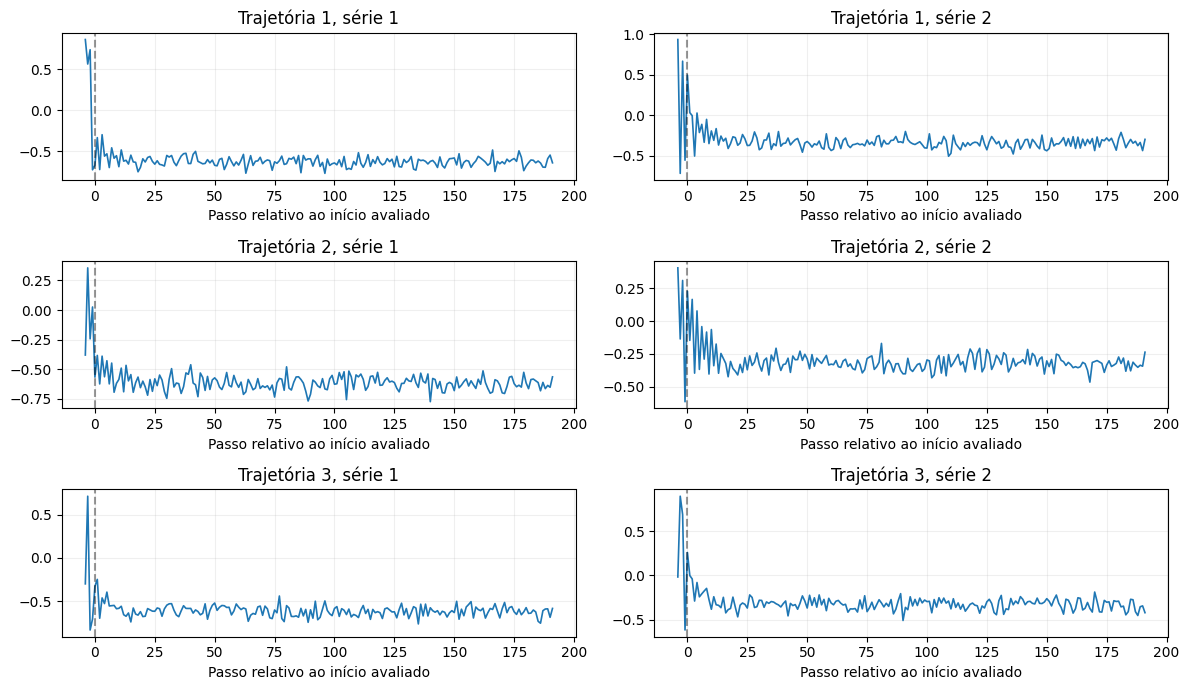

In [4]:
sample_paths = sample_shao_wu_trajectories
paths = sample_paths(DEMO, trajectory_count=3, generated_steps=192, root_seed=812)
fig, axes = plt.subplots(3, DEMO.num_series, figsize=(12, 7), squeeze=False)
for k in range(3):
    for j in range(DEMO.num_series):
        axis = axes[k, j]
        axis.plot(np.arange(-DEMO.order, 192), paths[k, j], lw=1.2)
        axis.axvline(0, color="black", ls="--", alpha=.4)
        axis.set(title=f"Trajetória {k+1}, série {j+1}", xlabel="Passo relativo ao início avaliado")
        axis.grid(alpha=.2)
fig.tight_layout()
plt.show()


**O que foi feito.** As colunas representam variáveis e as linhas, realizações do mesmo mecanismo. O histórico retido aparece à esquerda de zero.

## 3. Estabilidade operacional e velocidade

Explosão: valor não finito ou módulo acima de 100. Cauda de baixa amplitude: todas as variáveis dentro de [-0.15,0.15] nos últimos 24 passos. Os horizontes usam prefixos da mesma trajetória.

In [5]:
results = {"shao-wu": benchmark_stability_method(
    "shao-wu", mechanisms, root_seed=ROOT_SEED, diagnostic_config=DIAGNOSTIC_CONFIG,
    sampling_seconds=sampling_seconds,
)}
outcomes = pd.DataFrame([row for result in results.values() for row in result["outcomes"]])
performance = pd.DataFrame([result["performance"] for result in results.values()])
summary = outcomes.groupby(["method", "horizon"], sort=False).agg(
    N=("sample_index", "size"), explosions=("exploded", "sum"),
    explosion_rate=("exploded", "mean"), near_zero=("near_zero", "sum"),
    near_zero_rate=("near_zero", "mean"), neither=("neither", "sum"),
    nonfinite=("nonfinite", "sum"),
    finite_threshold_crossings=("finite_threshold_crossing", "sum"),
).reset_index()
for count, rate in (("explosions", "explosion"), ("near_zero", "near_zero")):
    intervals = [wilson_interval(int(k), int(n)) for k, n in zip(summary[count], summary["N"])]
    summary[rate + "_wilson_95_low"] = [v[0] for v in intervals]
    summary[rate + "_wilson_95_high"] = [v[1] for v in intervals]
display(summary)
display(performance)


,method,horizon,N,explosions,explosion_rate,near_zero,near_zero_rate,neither,nonfinite,finite_threshold_crossings,explosion_wilson_95_low,explosion_wilson_95_high,near_zero_wilson_95_low,near_zero_wilson_95_high
0,shao-wu,96,256,0,0.0,38,0.148438,218,0,0,0.0,0.014784,0.110095,0.197175
1,shao-wu,192,256,0,0.0,38,0.148438,218,0,0,0.0,0.014784,0.110095,0.197175
2,shao-wu,384,256,0,0.0,36,0.140625,220,0,0,0.0,0.014784,0.103337,0.188539


,method,mechanisms,sampling_and_certificate_seconds,mechanisms_per_second,initialization_seconds,innovation_seconds,ast_execution_seconds,diagnostic_seconds,evaluation_seconds,total_seconds,attempted_trajectories_per_second,successful_full_trajectories_per_second,full_horizon_success_rate,evaluated_steps,evaluated_values,ast_values_per_second,end_to_end_values_per_second
0,shao-wu,256,0.301883,848.010091,0.018453,0.012375,3.75222,0.031324,3.866876,4.16876,61.409152,61.409152,1.0,98304,196608,52397.784739,47162.229093


**O que foi feito.** A avaliação separa amostragem/certificação, inicialização, inovações, execução e diagnóstico. O tempo total inclui todos esses custos.

## Interpretação

O histórico inicial uniforme pode produzir um transiente; o certificado se refere à solução estacionária e ao esquecimento do passado. TANH mantém os produtos limitados e pode comprimir amplitudes e sensibilidades. O benchmark deve considerar essa mudança de família junto dos ganhos de estabilidade. Gaussianas admitem excursões grandes; cauda de baixa amplitude descreve uma janela finita.

## Registro completo do experimento

Configuração, sementes, proveniência, métricas, síntese e reprodução ficam nesta célula.

In [6]:
def git_output(*args):
    try:
        return subprocess.check_output(["git", *args], cwd=PROJECT_ROOT,
                                       text=True, stderr=subprocess.DEVNULL).strip()
    except (subprocess.CalledProcessError, FileNotFoundError):
        return None

source_paths = [
    "src/tsfmxai/representations/expression.py",
    "src/tsfmxai/generators/random_expression.py",
    "src/tsfmxai/generators/trajectory.py",
    "src/tsfmxai/generators/stochastic.py",
    "src/tsfmxai/generators/contraction.py",
    "src/tsfmxai/generators/shao_wu.py",
    "src/tsfmxai/generators/heaps.py",
    "src/tsfmxai/evaluation/stability.py",
    "src/tsfmxai/evaluation/generator_tradeoff.py",
]
record = {
    "experiment_id": EXPERIMENT_ID, "status": "executed",
    "research_question": RESEARCH_QUESTION,
    "hypothesis": HYPOTHESIS,
    "configuration": configuration,
    "seed_policy": {
        "mechanisms": "derive_sample_seed(ROOT_SEED, index)",
        "benchmark_initialization_and_future_noise": "SeedSequence([ROOT_SEED, index, 991]).spawn(2)",
        "multiple_trajectories": "SeedSequence([root_seed, trajectory_index]).spawn(2)",
        "external_global_rng": False,
        "note": "Per-index local streams isolate generation from user RNG state and worker scheduling.",
    },
    "provenance": {
        "git_head": git_output("rev-parse", "HEAD"), "dirty_worktree": bool(git_output("status", "--porcelain")),
        "source_sha256": {name: hashlib.sha256((PROJECT_ROOT / name).read_bytes()).hexdigest()
                          for name in source_paths},
        "python": sys.version, "platform": platform.platform(),
        "packages": {name: importlib.metadata.version(name)
                     for name in ("numpy", "pandas", "matplotlib", "joblib", "threadpoolctl")},
        "blas": threadpool_info(), "execution": "serial wall-clock; BLAS threads=1",
        "references": {"Shao-Wu": "https://arxiv.org/abs/math/0611029",
                       "Heaps": "https://arxiv.org/abs/2004.09455"},
    },
    "metrics": {"stability": json.loads(summary.to_json(orient="records")),
                "performance": json.loads(performance.to_json(orient="records")),
                "additional_checks": additional_checks},
    "scientific_summary": [
        f"{r.method}: h={r.horizon}, {r.explosions}/{r.N} threshold failures; "
        f"{r.near_zero}/{r.N} low-amplitude tails."
        for r in summary[summary.horizon.eq(max(HORIZONS))].itertuples()
    ],
    "limitations": [
        "near_zero means all final 24 values within +/-0.15, a finite-window low-amplitude label.",
        "Gaussian stationary samples may cross a finite threshold; threshold crossing and nonfinite outputs are recorded separately.",
        "One independent mechanism/realization per outcome denominator; Wilson intervals are over these samples.",
        "Families and native initialization/noise laws differ; matched variance does not make noise distributions identical.",
        "Shao-Wu starts from a direct uniform history and may have a finite-horizon transient; Heaps uses a joint invariant Gaussian history.",
        "Single-run timings include failed attempts; they are hardware-dependent, without timing confidence intervals.",
        "The mathematical mappings are published; random AST construction and explanation-ready storage are project adaptations.",
    ],
    "reproduction_command": (
        ".\\.venv\\Scripts\\python.exe -m jupyter nbconvert --to notebook --execute --inplace "
        + NOTEBOOK_PATH + " --ExecutePreprocessor.timeout=3600"
    ),
}
print(json.dumps(record, indent=2, ensure_ascii=False))


{
  "experiment_id": "shao_wu_gmc",
  "status": "executed",
  "research_question": "Como gerar mecanismos não lineares com certificado global e histórico inicial explícito?",
  "hypothesis": "As cotas globais limitam a influência do passado; o histórico uniforme pode produzir um transiente inicial.",
  "configuration": {
    "root_seed": 20261001,
    "count": 256,
    "method": {
      "tree_config": {
        "minimum_operators": 1,
        "maximum_operators": 6,
        "num_series": 2,
        "minimum_lag": 1,
        "maximum_lag": 4,
        "parameter_probability": 0.55,
        "time_probability": 0.0,
        "lag_probability": 0.45,
        "add_probability": 0.8,
        "minimum_parameter_magnitude": 0.05,
        "maximum_parameter_magnitude": 0.8,
        "require_lag": true,
        "require_time": false,
        "coefficient_gate_lags": false
      },
      "target_gain": 0.8,
      "safety_factor": 0.95,
      "innovation_std": 0.05,
      "initial_radius": 1.0,
    

**O que foi feito.** Os resultados e hashes das fontes ficam incorporados ao notebook executado, sem sidecars duplicados.